# Pneumonia Classification from Chest X-Rays — Basic ML, Phase 1
## One notebook: literature → EDA → features → scaling → training → validation

**Aim:** distinguish the dataset's NORMAL and PNEUMONIA labels using a small, understandable classical ML pipeline.

**What is implemented from scratch:** patient-proxy grouping, fold assignment, feature extraction, scaling, majority baseline, Gaussian Naive Bayes, logistic regression, gradient descent, model selection, confusion counts, metrics, ROC curve and bootstrap intervals. **No scikit-learn, pandas, OpenCV, SciPy, TensorFlow, PyTorch, pretrained models or optimizer packages are used.**

**Supporting libraries:** Pillow only decodes/resizes JPEGs; NumPy supplies arrays and arithmetic; Matplotlib plots results. Python standard-library modules handle files, hashes, ZIPs and downloads. IPython's display utility is part of the notebook environment and only shows saved plots. These tools do not train the models for us. Strictly library-free Python cannot conveniently decode this JPEG dataset; the ML itself is explicit.

**How to run:** in Colab choose CPU and Run all. The data cell first looks for the image folder and, if absent, attempts the public Kaggle archive using Python's standard library. If Kaggle requires authentication, upload/extract your downloaded archive under `/content/data/chest_xray` and rerun. Local execution automatically uses `~/Downloads/chest_xray`. Results go to a separate `basic_phase1` folder; this experiment does not reuse the earlier sklearn scores.

**What to tell the instructor:** “We chose a simple supervised binary classifier, engineered interpretable image summaries, fitted scaling only on training folds, selected the model using grouped cross-validation, then evaluated a held-out test with multiple metrics.” This is a student benchmark, not a clinical diagnostic tool.

## 1. Literature review — what prior work teaches us

[Kermany et al., Cell (2018)](https://doi.org/10.1016/j.cell.2018.02.010) motivates the pediatric pneumonia image classification task and provides dataset provenance. Its deep-learning experiments show the relevance of image-based classification, but their published results are not equivalent to our simpler features or our audited partitions.

[Ng & Jordan, NeurIPS (2001)](https://papers.nips.cc/paper_files/paper/2001/hash/7b7a53e239400a13bd6be6c91c4f6c4e-Abstract.html) compares discriminative logistic regression with generative Naive Bayes and discusses their different statistical behavior. It motivates our comparison; it does not guarantee that either wins on these images.

[Hastie, Tibshirani & Friedman, The Elements of Statistical Learning](https://hastie.su.domains/ElemStatLearn/main.html), especially the classification and model-assessment chapters, supplies the framework for regularization, validation and bias/variance. We apply those principles with explicit code.

[Zech et al., PLOS Medicine (2018)](https://doi.org/10.1371/journal.pmed.1002683) shows radiological models can exploit acquisition/hospital differences and lose performance externally. It motivates overlap auditing, cautious interpretation and the need for external validation.

**Our question:** do simple regional brightness/contrast features plus logistic regression outperform a majority baseline and Gaussian Naive Bayes? **Contribution for Phase 1:** explain every calculation, compare basic alternatives fairly, and report limitations rather than pursue a headline accuracy. No claims of matching published deep-learning results are made.

**Alternatives:** HOG/LBP could encode texture more richly, PCA could reduce features, SVM or a tree could model other boundaries, and CNNs could learn features automatically. We start with regional summaries and two basic models because their assumptions and training steps are easier to derive and defend. They trade representational power for simplicity.

## 2. Import only supporting libraries

NumPy does vector arithmetic, Pillow reads pixels, and Matplotlib draws figures. The model code below never calls an ML estimator or library metric.

In [1]:
import sys, csv, json, hashlib, re, zipfile, shutil, urllib.request, importlib.util, platform
from collections import Counter
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Image as NotebookImage

SEED = 42
LABELS = {'NORMAL': 0, 'PNEUMONIA': 1}
IN_COLAB = importlib.util.find_spec('google.colab') is not None
print('Environment:', 'Google Colab' if IN_COLAB else 'Local Python')
print('NumPy is used for arithmetic; all ML operations are implemented below.')

Environment: Local Python
NumPy is used for arithmetic; all ML operations are implemented below.


## 3. Find or download the dataset

We use the actual downloaded images. Colab runs on a remote machine and cannot read a Mac Downloads folder. The optional public archive download avoids requiring an extra Kaggle client library. No credential is embedded. If downloading is blocked, the cell fails with a clear upload instruction; it never substitutes fabricated data.

In [2]:
PROJECT_ROOT = Path('/content') if IN_COLAB else Path.cwd()
if PROJECT_ROOT.name == 'Notebooks': PROJECT_ROOT = PROJECT_ROOT.parent
OUTPUT = PROJECT_ROOT / 'basic_phase1'
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES = OUTPUT / 'figures'
FIGURES.mkdir(exist_ok=True)
DATA_ROOT = Path('/content/data/chest_xray') if IN_COLAB else Path.home() / 'Downloads/chest_xray'

if IN_COLAB and not DATA_ROOT.exists():
    existing = [Path('/content/chest_xray'), Path('/content/drive/MyDrive/chest_xray')]
    DATA_ROOT = next((p for p in existing if p.exists()), DATA_ROOT)
if IN_COLAB and not DATA_ROOT.exists():
    archive = Path('/content/chest_xray_kaggle.zip')
    url = 'https://www.kaggle.com/api/v1/datasets/download/paultimothymooney/chest-xray-pneumonia'
    print('Downloading public Kaggle archive; this may take several minutes...', flush=True)
    if not archive.exists() or not zipfile.is_zipfile(archive):
        try:
            request = urllib.request.Request(url, headers={'User-Agent': 'Python phase1 educational notebook'})
            with urllib.request.urlopen(request, timeout=90) as response, archive.open('wb') as f:
                shutil.copyfileobj(response, f)
        except Exception as exc:
            raise RuntimeError('Download unavailable. Upload/extract your chest_xray archive under /content/data/chest_xray and rerun.') from exc
    if not zipfile.is_zipfile(archive):
        raise RuntimeError('Kaggle did not return a ZIP. Upload the downloaded dataset archive manually.')
    destination = Path('/content/data').resolve()
    destination.mkdir(exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        # Extract only the shortest canonical tree, ignoring the nested duplicate.
        names = [n for n in z.namelist() if '/train/NORMAL/' in n and n.lower().endswith(('.jpeg','.jpg','.png')) and '__MACOSX' not in n]
        if not names: raise ValueError('Archive has no expected chest_xray/train/NORMAL images')
        prefix = min((n.split('/train/NORMAL/')[0] for n in names), key=len)
        for item in z.infolist():
            relative = item.filename[len(prefix)+1:] if item.filename.startswith(prefix+'/') else ''
            if relative.startswith(('train/','val/','test/')) and relative.lower().endswith(('.jpeg','.jpg','.png')) and not Path(relative).name.startswith('._'):
                target = (destination/'chest_xray'/relative).resolve()
                if not target.is_relative_to(destination): raise ValueError('Unsafe archive path')
                target.parent.mkdir(parents=True, exist_ok=True)
                with z.open(item) as src, target.open('wb') as dst: shutil.copyfileobj(src,dst)
    DATA_ROOT = destination/'chest_xray'
print('Dataset:', DATA_ROOT)
print('Output folder:', OUTPUT)

Dataset: /Users/ravichandrashinde/Downloads/chest_xray
Output folder: /Users/ravichandrashinde/Chest-Xray-Pneumonia-ML/basic_phase1


## 4. Dataset quality — readable images, duplicates and group overlap

**Why this step?** Training on duplicates or images of an apparent patient also present in test can inflate results. We decode one canonical tree, check pixel hashes and connect matching filename proxies or exact image hashes.

**Policy fixed before training:** keep test-linked groups out of development; remove label-conflicting exact duplicates; keep one remaining exact pixel copy. The tiny supplied validation folder joins development. Raw images are never changed.

**Alternative:** a random image split is simpler but may put repeated patient images into both partitions. A verified patient split is preferable, but verified identifiers are unavailable. Filename groups are only conservative proxies: collisions or unrecognized repeat patients can remain. Exact hashing does not identify every near duplicate.

In [3]:
def write_csv(path, rows):
    if not rows:
        return
    with Path(path).open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def patient_proxy(name):
    """A conservative filename grouping, NOT verified clinical identity."""
    stem = Path(name).stem
    match = re.match(r"(person\d+)_", stem)
    if match:
        return match.group(1)
    match = re.match(r"((?:NORMAL2-)?IM-\d+)", stem)
    return match.group(1) if match else "unknown:" + stem


def find_root(path):
    path = Path(path).expanduser().resolve()
    for candidate in (path, path / "chest_xray", path / "chest_xray/chest_xray"):
        if all((candidate / split / label).is_dir()
               for split in ("train", "val", "test") for label in LABELS):
            return candidate
    raise FileNotFoundError(f"Expected train/val/test, each with NORMAL/PNEUMONIA: {path}")


def audit_images(data_root):
    """Decode exactly one tree, identify duplicate pixels and link groups."""
    root = find_root(data_root)
    records, failures = [], []
    for split in ("train", "val", "test"):
        for label, target in LABELS.items():
            for path in sorted((root / split / label).iterdir()):
                if path.suffix.lower() not in (".jpeg", ".jpg", ".png") or path.name.startswith("._"):
                    continue
                try:
                    with Image.open(path) as im:
                        im.load()
                        pixels = np.asarray(im.convert("L"))
                        digest = hashlib.sha256(str(pixels.shape).encode() + pixels.tobytes()).hexdigest()
                        records.append(dict(path=str(path.relative_to(root)), split=split,
                            label=label, target=target, width=im.width, height=im.height,
                            mode=im.mode, brightness=float(pixels.mean()),
                            contrast=float(pixels.std()), dark_fraction=float((pixels <= 5).mean()),
                            bright_fraction=float((pixels >= 250).mean()),
                            pixel_hash=digest, patient_proxy=patient_proxy(path.name)))
                except (OSError, ValueError) as exc:
                    failures.append(dict(path=str(path.relative_to(root)), error=str(exc)))
    if not records:
        raise ValueError("No readable images")
    parent = list(range(len(records)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    # Connected groups prevent a chain of duplicate/patient links crossing folds.
    for field in ("patient_proxy", "pixel_hash"):
        seen = {}
        for i, row in enumerate(records):
            key = row[field]
            if key in seen:
                parent[find(i)] = find(seen[key])
            else:
                seen[key] = i
    hash_labels = {}
    for i, row in enumerate(records):
        row["group"] = f"group_{find(i)}"
        hash_labels.setdefault(row["pixel_hash"], set()).add(row["target"])
    conflicts = {h for h, labels in hash_labels.items() if len(labels) > 1}
    test_groups = {r["group"] for r in records if r["split"] == "test"}
    seen_hashes = set()
    for row in records:
        reason = ""
        if row["split"] != "test" and row["group"] in test_groups:
            reason = "group_overlap_with_test"
        if row["pixel_hash"] in conflicts:
            reason = "conflicting_duplicate_label"
        if not reason:
            if row["pixel_hash"] in seen_hashes:
                reason = "exact_pixel_duplicate"
            else:
                seen_hashes.add(row["pixel_hash"])
        row["exclusion"] = reason
        row["partition"] = "excluded" if reason else ("test" if row["split"] == "test" else "development")
    return root, records, failures



root, records, failures = audit_images(DATA_ROOT)
write_csv(OUTPUT/'image_audit.csv', records)
if failures: write_csv(OUTPUT/'unreadable_images.csv', failures)
print('Readable images:', len(records), '| Decode failures:', len(failures))
print('Original split/class counts:', dict(Counter((r['split'],r['label']) for r in records)))
print('Repeated decoded-pixel images:', len(records)-len({r['pixel_hash'] for r in records}))
print('Excluded images:', dict(Counter(r['exclusion'] for r in records if r['exclusion'])))
retained = [r for r in records if r['partition']!='excluded']
print('Retained partition/class counts:', dict(Counter((r['partition'],r['label']) for r in retained)))

Readable images: 5856 | Decode failures: 0
Original split/class counts: {('train', 'NORMAL'): 1341, ('train', 'PNEUMONIA'): 3875, ('val', 'NORMAL'): 8, ('val', 'PNEUMONIA'): 8, ('test', 'NORMAL'): 234, ('test', 'PNEUMONIA'): 390}
Repeated decoded-pixel images: 32
Excluded images: {'exact_pixel_duplicate': 28, 'group_overlap_with_test': 457}
Retained partition/class counts: {('development', 'NORMAL'): 1348, ('development', 'PNEUMONIA'): 3405, ('test', 'NORMAL'): 231, ('test', 'PNEUMONIA'): 387}


## 5. EDA — sizes, missing metadata and class balance

Count labels and examine dimensions before deciding how to represent an image. Clinical age/sex/site/verified patient fields are unavailable; they are not filled with guesses. Class imbalance motivates a majority baseline and balanced accuracy.

width: min=384.00, median=1281.00, mean=1327.88, max=2916.00
height: min=127.00, median=888.00, mean=970.69, max=2713.00
brightness: min=58.72, median=122.75, mean=122.79, max=221.54
contrast: min=20.42, median=57.33, mean=56.99, max=87.48
Missing recorded metadata: 0
Not supplied: clinical age, sex, acquisition site, verified patient identity.


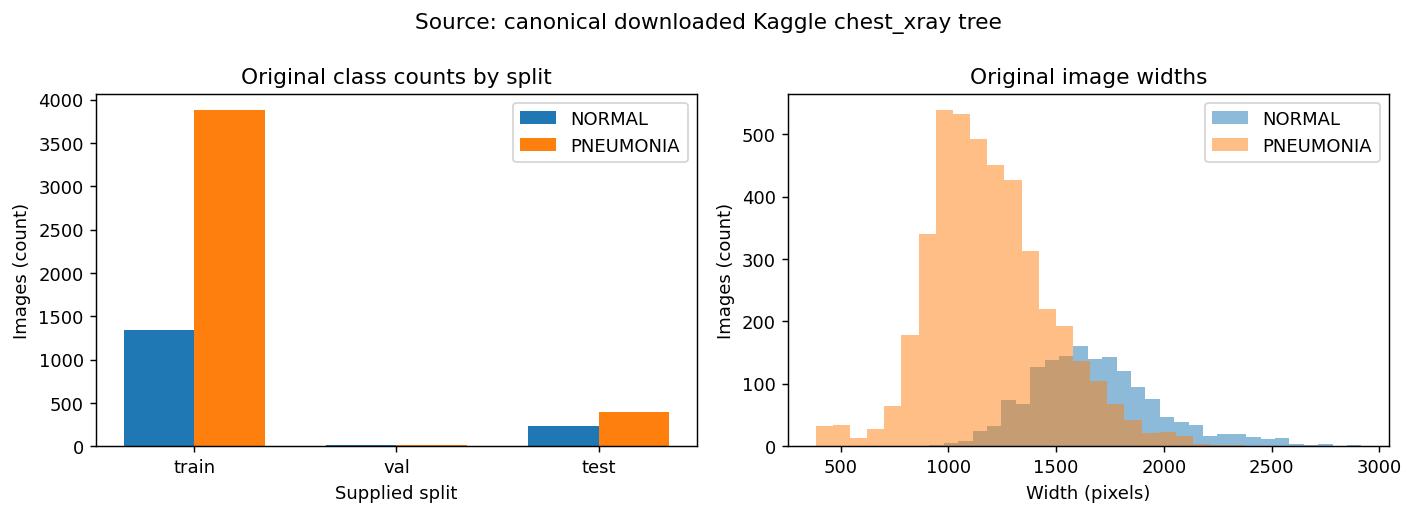

In [4]:
def show_figure(filename):
    plt.tight_layout()
    plt.savefig(FIGURES/filename, dpi=130, bbox_inches='tight')
    plt.close()
    display(NotebookImage(filename=str(FIGURES/filename)))

for key in ('width','height','brightness','contrast'):
    values=np.array([r[key] for r in records])
    print(f'{key}: min={values.min():.2f}, median={np.median(values):.2f}, mean={values.mean():.2f}, max={values.max():.2f}')
print('Missing recorded metadata:', sum(v is None for r in records for v in r.values()))
print('Not supplied: clinical age, sex, acquisition site, verified patient identity.')
fig,axes=plt.subplots(1,2,figsize=(11,4))
splits=['train','val','test']; location=np.arange(3)
for j,label in enumerate(LABELS):
    values=[sum(r['split']==s and r['label']==label for r in records) for s in splits]
    axes[0].bar(location+(j-.5)*.35,values,width=.35,label=label)
    for ax,key in [(axes[1],'width')]:
        ax.hist([r[key] for r in records if r['label']==label],bins=30,alpha=.5,label=label)
axes[0].set_xticks(location,splits)
axes[0].set(title='Original class counts by split',xlabel='Supplied split',ylabel='Images (count)')
axes[1].set(title='Original image widths',xlabel='Width (pixels)',ylabel='Images (count)')
for ax in axes: ax.legend()
fig.suptitle('Source: canonical downloaded Kaggle chest_xray tree')
show_figure('01_class_balance_and_sizes.png')

## 6. EDA — brightness, contrast and split differences

Image acquisition can affect brightness and contrast. We describe these differences, without treating them as proven disease markers. Test summaries are an audit only; the feature set and experiment settings remain fixed. No test outcome chooses a model.

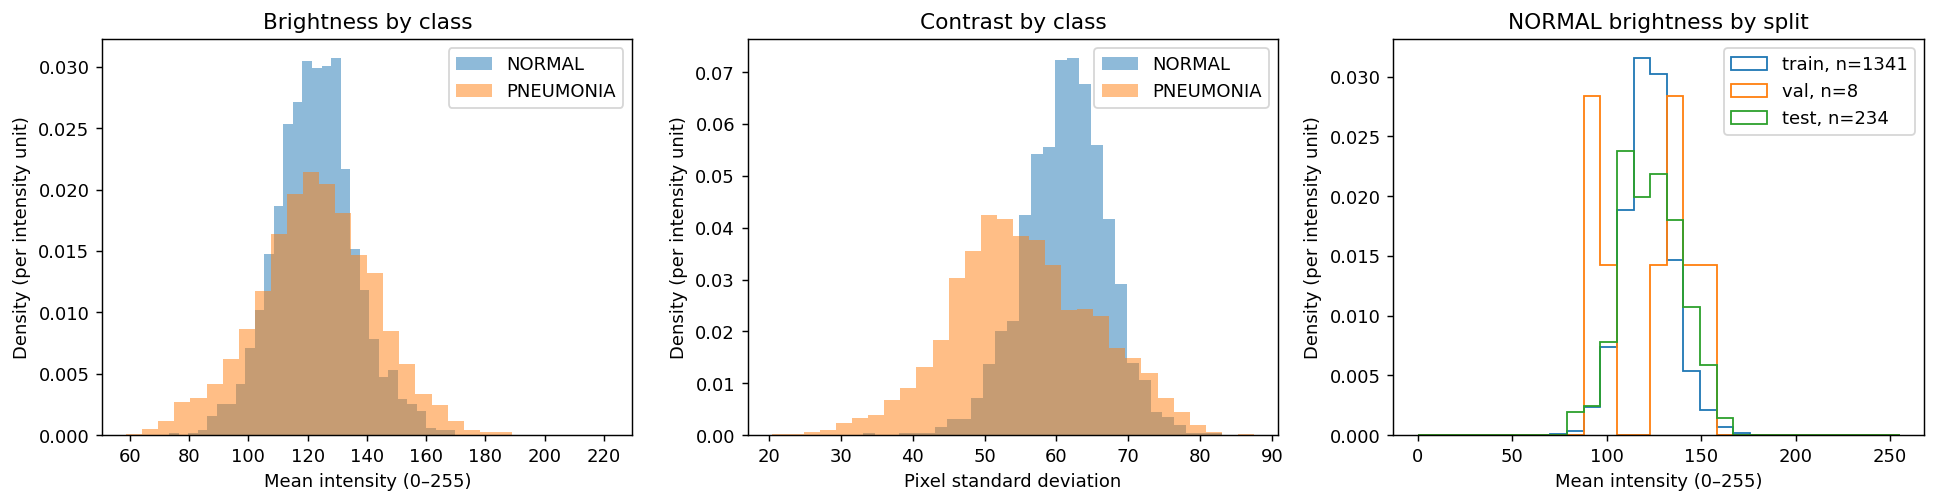

In [5]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for label in LABELS:
    part=[r for r in records if r['label']==label]
    axes[0].hist([r['brightness'] for r in part],bins=30,density=True,alpha=.5,label=label)
    axes[1].hist([r['contrast'] for r in part],bins=30,density=True,alpha=.5,label=label)
for split in ['train','val','test']:
    values=[r['brightness'] for r in records if r['split']==split and r['label']=='NORMAL']
    axes[2].hist(values,bins=np.linspace(0,255,30),density=True,histtype='step',label=f'{split}, n={len(values)}')
axes[0].set(title='Brightness by class',xlabel='Mean intensity (0–255)',ylabel='Density (per intensity unit)')
axes[1].set(title='Contrast by class',xlabel='Pixel standard deviation',ylabel='Density (per intensity unit)')
axes[2].set(title='NORMAL brightness by split',xlabel='Mean intensity (0–255)',ylabel='Density (per intensity unit)')
for ax in axes: ax.legend()
show_figure('02_intensity_and_split_eda.png')

## 7. EDA — inspect representative images

Seeded development examples avoid cherry-picking unusually clear cases. Labels are inherited dataset annotations; these plots cannot independently verify diagnosis.

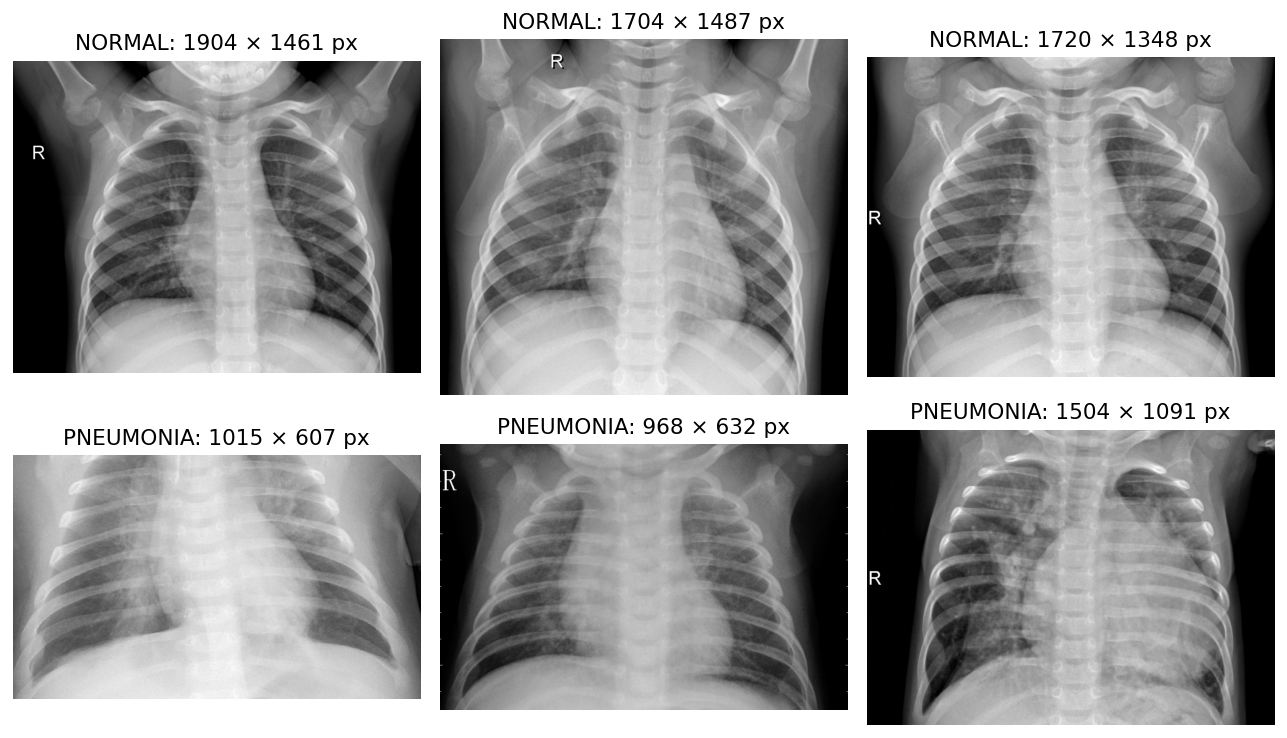

In [6]:
rng=np.random.default_rng(SEED)
fig,axes=plt.subplots(2,3,figsize=(10,6))
for i,label in enumerate(LABELS):
    available=[r for r in retained if r['partition']=='development' and r['label']==label]
    chosen=rng.choice(len(available),size=3,replace=False)
    for ax,index in zip(axes[i],chosen):
        row=available[index]
        with Image.open(root/row['path']) as im: ax.imshow(im.convert('L'),cmap='gray')
        ax.set_title(f"{label}: {row['width']} × {row['height']} px"); ax.axis('off')
show_figure('03_example_images.png')

## 8. Feature engineering — explainable regional summaries

**Chosen:** grayscale, aspect-preserving resize/padding to 64×64, then divide pixel values by 255. Split the image into an 8×8 grid. For each block compute mean brightness and standard deviation: **64 means + 64 contrasts**. Add **16 histogram proportions + 5 global summaries = 149 features**.

**Why?** A radiograph contains spatial information; regional means retain coarse location while contrasts describe local variation. Histograms summarize the intensity distribution. These features have clear definitions and make basic ML training fast on CPU.

**Alternatives and tradeoffs:** raw 64×64 pixels give 4,096 correlated inputs; HOG/LBP add richer texture but more explanation and implementation; PCA reduces dimension but learns a less directly interpretable representation; CNNs learn features but exceed this basic Phase 1 scope. Regional summaries discard subtle details and can retain padding/marker shortcuts. No claim is made that they isolate pneumonia-specific pathology.

**Normalization vs scaling:** division by 255 is fixed per-image normalization. Standardization later learns training-set means and standard deviations. Filenames, original dimensions, group IDs and split labels are never predictors.

In [7]:
def make_features(path):
    """149 simple features: regional mean/std, histogram and global summaries."""
    with Image.open(path) as im:
        image = ImageOps.pad(im.convert("L"), (64, 64), method=Image.Resampling.BILINEAR, color=0)
        pixels = np.asarray(image, dtype=np.float64) / 255.0
    # 8x8 blocks; every block contains 8x8 normalized pixels.
    blocks = pixels.reshape(8, 8, 8, 8).transpose(0, 2, 1, 3)
    means = blocks.mean(axis=(2, 3)).ravel()
    stds = blocks.std(axis=(2, 3)).ravel()
    histogram = np.histogram(pixels, bins=16, range=(0, 1))[0] / pixels.size
    summaries = [pixels.mean(), pixels.std(), np.median(pixels),
                 np.abs(np.diff(pixels, axis=0)).mean(),
                 np.abs(np.diff(pixels, axis=1)).mean()]
    return np.concatenate([means, stds, histogram, summaries])


def feature_names():
    return ([f"block_mean_r{r}_c{c}" for r in range(8) for c in range(8)]
            + [f"block_std_r{r}_c{c}" for r in range(8) for c in range(8)]
            + [f"histogram_bin_{i}" for i in range(16)]
            + ["global_mean", "global_std", "global_median", "vertical_difference", "horizontal_difference"])



names=feature_names()
X=np.stack([make_features(root/r['path']) for r in retained])
y=np.array([r['target'] for r in retained],dtype=int)
groups=np.array([r['group'] for r in retained])
is_dev=np.array([r['partition']=='development' for r in retained])
assert X.shape[1]==len(names)==149 and np.isfinite(X).all()
print('Features:',X.shape,'| Label counts:',dict(Counter(y.tolist())))
print('Last five feature names:',names[-5:])
np.savez_compressed(OUTPUT/'basic_features.npz',X=X,y=y,groups=groups,is_development=is_dev)

Features: (5371, 149) | Label counts: {0: 1579, 1: 3792}
Last five feature names: ['global_mean', 'global_std', 'global_median', 'vertical_difference', 'horizontal_difference']


## 9. Training and validation design — protect the test

We combine the tiny supplied validation folder with training into **development**. Three approximately stratified group folds compare models on the same rows. Each patient/hash proxy stays in one fold. The code shuffles deterministically, places larger groups first and balances each group's majority class; this is a simple explicit algorithm rather than an optimal stratification guarantee.

**Why three folds?** More robust than a single split while keeping the experiment small. Five-fold CV is a reasonable more expensive alternative. Nested CV would better estimate the selected model's development performance; we instead state that development scores are selection-biased and reserve the test for the fixed final choice.

**Fixed before training:** seed 42; logistic λ in {0.01, 0.1}; three folds; class-balanced training; selection by mean balanced accuracy; classification threshold 0.5. No test-tuned threshold is used.

In [8]:
def fit_scaler(x):
    """Learn only from the supplied training rows; guard constant columns."""
    mean, std = x.mean(axis=0), x.std(axis=0)
    return {"mean": mean, "std": np.where(std < 1e-12, 1.0, std)}


def scale(x, scaler):
    return (x - scaler["mean"]) / scaler["std"]


def grouped_folds(y, groups, n_folds=3, seed=SEED):
    """Greedy class-balanced group assignment, implemented without sklearn.

    Shuffle groups, then allocate largest groups first to the fold with the
    fewest samples from that group's majority class. Stable sorting makes
    ties randomized but reproducible. Stratification is approximate.
    """
    rng = np.random.default_rng(seed)
    grouped = {}
    for i, group in enumerate(groups):
        grouped.setdefault(str(group), []).append(i)
    assignment = np.full(len(y), -1, dtype=int)
    counts = np.zeros((n_folds, 2), dtype=int)
    for label in (0, 1):
        items = [(g, ids) for g, ids in grouped.items()
                 if int(y[ids].mean() >= 0.5) == label]
        rng.shuffle(items)
        items.sort(key=lambda item: len(item[1]), reverse=True)
        for group, ids in items:
            fold = int(np.argmin(counts[:, label]))
            assignment[ids] = fold
            counts[fold] += np.bincount(y[ids], minlength=2)
    folds = []
    for fold in range(n_folds):
        tr, va = np.flatnonzero(assignment != fold), np.flatnonzero(assignment == fold)
        assert not set(groups[tr]) & set(groups[va])
        assert len(np.unique(y[tr])) == len(np.unique(y[va])) == 2
        folds.append((tr, va))
    return folds, assignment



Xd,yd,gd=X[is_dev],y[is_dev],groups[is_dev]
Xt,yt,gt=X[~is_dev],y[~is_dev],groups[~is_dev]
assert not set(gd)&set(gt)
assert not ({r['pixel_hash'] for r in retained if r['partition']=='development'} & {r['pixel_hash'] for r in retained if r['partition']=='test'})
folds,assignment=grouped_folds(yd,gd)
for number,(tr,va) in enumerate(folds):
    print(f'Fold {number}: train={len(tr)}, validation={len(va)}, validation positive fraction={yd[va].mean():.3f}')
write_csv(OUTPUT/'development_folds.csv',[dict(path=r['path'],group=r['group'],target=r['target'],fold=int(assignment[i])) for i,r in enumerate([r for r in retained if r['partition']=='development'])])
print('Development:',len(yd),'| Reserved test:',len(yt),'| Group overlap: 0')

Fold 0: train=3168, validation=1585, validation positive fraction=0.716
Fold 1: train=3169, validation=1584, validation positive fraction=0.717
Fold 2: train=3169, validation=1584, validation positive fraction=0.717
Development: 4753 | Reserved test: 618 | Group overlap: 0


## 10. Feature scaling from scratch

For each feature, compute **z = (x − training mean) / training standard deviation**. If a column is constant, use divisor 1 so it remains finite.

**Why standardize?** Features such as histogram proportions and regional contrast have different scales. Gradient descent and L2 regularization behave more consistently after standardization. **Alternative:** min–max scaling is understandable but sensitive to extreme values; no scaling leaves unequal numerical influence. Trees would not require standardization.

The demonstration fits fold 0 training rows only. Every model/CV fit later learns its own scaler; no globally standardized development matrix is reused across folds.

Largest absolute standardized training mean: 1.8780396710274567e-14
Validation means need not be zero: 0.03401034680289646
block_mean_r0_c0 : original std= 0.0864 , scaled std= 1.0
block_std_r0_c0 : original std= 0.0812 , scaled std= 1.0
histogram_bin_0 : original std= 0.114 , scaled std= 1.0
global_mean : original std= 0.0806 , scaled std= 1.0


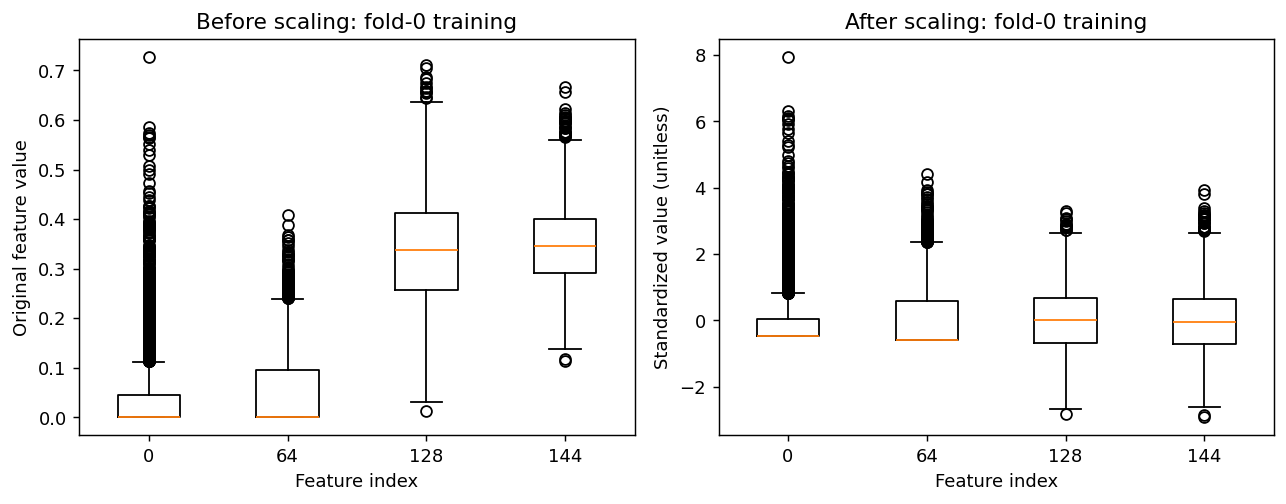

In [9]:
tr,va=folds[0]
demo_scaler=fit_scaler(Xd[tr])
train_z=scale(Xd[tr],demo_scaler)
validation_z=scale(Xd[va],demo_scaler)
print('Largest absolute standardized training mean:',np.abs(train_z.mean(axis=0)).max())
print('Validation means need not be zero:',np.abs(validation_z.mean(axis=0)).mean())
for index in [0,64,128,144]:
    print(names[index],': original std=',round(Xd[tr,index].std(),4),', scaled std=',round(train_z[:,index].std(),4))
fig,axes=plt.subplots(1,2,figsize=(10,4))
columns=[0,64,128,144]
axes[0].boxplot(Xd[tr][:,columns],tick_labels=[str(c) for c in columns])
axes[1].boxplot(train_z[:,columns],tick_labels=[str(c) for c in columns])
axes[0].set(title='Before scaling: fold-0 training',xlabel='Feature index',ylabel='Original feature value')
axes[1].set(title='After scaling: fold-0 training',xlabel='Feature index',ylabel='Standardized value (unitless)')
show_figure('04_scaling_from_scratch.png')

## 11. Theoretical rigor — logistic regression and gradient descent

Logistic regression is a **classifier**, despite its name. It models a score $p=1/(1+e^{-(w^Tz+b)})$. We classify pneumonia when $p\ge0.5$.

Our exact objective is
$$J(w,b)=\frac1n\sum_i a_i[\log(1+e^{s_i})-y_i s_i]+\frac\lambda2\sum_j w_j^2,\quad s_i=w^Tz_i+b.$$
Class weights are $a_i=n/(2n_{y_i})$ and are computed from the current training fold. The bias is not penalized. Its gradients are
$$\nabla_wJ=Z^T[a\odot(p-y)]/n+\lambda w,\quad \partial J/\partial b=\operatorname{mean}(a\odot(p-y)).$$
Update $w\leftarrow w-\eta\nabla_wJ$ and similarly for $b$. Backtracking halves the learning rate when an update increases the objective. Stop at 1,000 iterations or improvement below $10^{-8}$. Record the objective so convergence is inspectable.

**Why this model?** A linear boundary, transparent loss, explicit gradients and a small number of settings make it a strong teaching baseline. L2 regularization discourages large coefficients and can reduce variance; larger λ means more shrinkage and potentially more bias. **Alternatives:** unregularized logistic regression may overfit; kNN avoids gradient optimization but requires distance/neighbor choices and more prediction-time work; SVM introduces margin loss; trees capture interactions but require split/depth choices.

**Why class weighting?** It gives each class equal total training influence without creating synthetic radiographs. **Alternatives:** oversampling duplicates training images, undersampling discards information, SMOTE creates synthetic feature vectors without assured radiological meaning. Class weighting changes the objective and probability interpretation: these scores are not established calibrated clinical probabilities.

In [10]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -50, 50)))


def logistic_objective(x, y, w, b, regularization, sample_weight):
    z = x @ w + b
    return float(np.mean(sample_weight * (np.logaddexp(0.0, z) - y * z))
                 + 0.5 * regularization * np.dot(w, w))


def train_logistic(x, y, regularization=0.01, max_iter=1000, learning_rate=0.2):
    """Full-batch gradient descent with backtracking; no optimizer library."""
    n, d = x.shape
    counts = np.bincount(y, minlength=2)
    sample_weight = n / (2.0 * counts[y])
    w, b = np.zeros(d), 0.0
    history = []
    for iteration in range(max_iter):
        old_loss = logistic_objective(x, y, w, b, regularization, sample_weight)
        error = sample_weight * (sigmoid(x @ w + b) - y)
        dw = x.T @ error / n + regularization * w
        db = float(error.mean())
        step = learning_rate
        for _ in range(30):
            new_w, new_b = w - step * dw, b - step * db
            loss = logistic_objective(x, y, new_w, new_b, regularization, sample_weight)
            if loss <= old_loss:
                break
            step *= 0.5
        if loss > old_loss:
            raise ArithmeticError("Gradient step failed to reduce objective")
        w, b = new_w, new_b
        history.append(loss)
        if abs(old_loss - loss) < 1e-8:
            break
    return {"kind": "logistic", "w": w, "b": b, "lambda": regularization,
            "loss_history": history, "iterations": len(history)}

## 12. Model alternatives — majority and Gaussian Naive Bayes

**Majority baseline:** always predict the most common development class. It shows why accuracy can look respectable without useful discrimination; balanced accuracy is 0.5 when both classes occur.

**Gaussian Naive Bayes:** estimate a mean and variance for each feature within each class, assume conditional feature independence, then sum Gaussian log-likelihoods and log priors. Use equal priors to represent equal class importance, and a fixed variance floor $10^{-3}$ in standardized squared units to prevent division by zero.

**Why include it?** It is a basic, fast model with closed-form training, contrasting generative assumptions with logistic regression's discriminative objective. **Limitation:** adjacent block features are correlated, so the independence assumption is approximate and scores may be overconfident. **Alternative:** empirical priors reflect development prevalence but emphasize its majority class. A full covariance Gaussian model represents correlations but estimates many more parameters.

In [11]:
def train_naive_bayes(x, y, variance_floor=1e-3):
    """Gaussian NB: class means/variances and equal class priors.

    Variance floor is in standardized squared feature units. Equal priors
    target equal class importance rather than dataset class prevalence.
    """
    means = np.stack([x[y == label].mean(axis=0) for label in (0, 1)])
    variances = np.stack([x[y == label].var(axis=0) for label in (0, 1)])
    return {"kind": "naive_bayes", "means": means,
            "variances": np.maximum(variances, variance_floor), "prior": np.array([0.5, 0.5])}


def predict_score(model, x):
    if model["kind"] == "majority":
        return np.full(len(x), model["score"], dtype=float)
    if model["kind"] == "logistic":
        return sigmoid(x @ model["w"] + model["b"])
    log_scores = []
    for label in (0, 1):
        var, mean = model["variances"][label], model["means"][label]
        log_density = -0.5 * (np.log(2 * np.pi * var) + (x - mean) ** 2 / var).sum(axis=1)
        log_scores.append(np.log(model["prior"][label]) + log_density)
    return sigmoid(log_scores[1] - log_scores[0])


def train_model(name, x, y, regularization=0.01):
    if name == "majority":
        return {"kind": "majority", "score": float(y.mean() >= 0.5)}
    if name == "gaussian_naive_bayes":
        return train_naive_bayes(x, y)
    return train_logistic(x, y, regularization=regularization)

## 13. Evaluation metrics — implement and understand them

Positive class is PNEUMONIA. We calculate TP, TN, FP and FN explicitly.

- Accuracy: (TP+TN)/all cases.
- Recall/sensitivity: TP/(TP+FN); how many annotated pneumonia images are detected.
- Specificity: TN/(TN+FP); how many normal images are correctly recognized.
- Precision: TP/(TP+FP); fraction of positive predictions that match the annotation.
- F1: harmonic mean of precision and recall.
- Balanced accuracy: mean of recall and specificity; this is our model-selection metric.
- ROC-AUC: trapezoidal area under true-positive rate vs false-positive rate, grouping equal scores together.

**Why more than accuracy?** The labels are imbalanced and false positives/false negatives reveal different errors. Precision varies with prevalence. AUC measures ranking and does not establish a useful clinical operating point. **Alternative:** select by accuracy or F1, but either can obscure poor normal-class performance. A clinical sensitivity target would require domain validation; we do not invent one.

In [12]:
def roc_points(y, score):
    """Threshold groups handle tied scores together; no rank-metric package."""
    order = np.argsort(-score, kind="stable")
    ys, ss = y[order], score[order]
    ends = np.r_[np.flatnonzero(ss[:-1] != ss[1:]), len(y) - 1]
    tp = np.r_[0, np.cumsum(ys)[ends]]
    fp = np.r_[0, np.cumsum(1 - ys)[ends]]
    return fp / (y == 0).sum(), tp / (y == 1).sum()


def metrics(y, score, threshold=0.5):
    prediction = (score >= threshold).astype(int)
    tp = int(((y == 1) & (prediction == 1)).sum())
    tn = int(((y == 0) & (prediction == 0)).sum())
    fp = int(((y == 0) & (prediction == 1)).sum())
    fn = int(((y == 1) & (prediction == 0)).sum())
    recall = tp / max(tp + fn, 1)
    specificity = tn / max(tn + fp, 1)
    precision = tp / max(tp + fp, 1)
    fpr, tpr = roc_points(y, score)
    auc = float(np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2))
    return dict(accuracy=(tp + tn) / len(y), balanced_accuracy=(recall + specificity) / 2,
                precision=precision, recall=recall, specificity=specificity,
                f1=2 * precision * recall / max(precision + recall, 1e-12), roc_auc=auc,
                tn=tn, fp=fp, fn=fn, tp=tp)

## 14. Validate the mathematics before fitting images

Check perfect, reversed and tied ROC-AUC; majority balanced accuracy; constant-column scaling; and loss reduction. A finite-difference check verifies the derived logistic gradient independently. These checks validate the implementation, not clinical usefulness.

In [13]:
def verify_math():
    """Independent mathematical checks for the hand-written ML operations."""
    y = np.array([0, 0, 1, 1])
    assert metrics(y, np.array([0.1, 0.2, 0.8, 0.9]))["roc_auc"] == 1.0
    assert metrics(y, np.array([0.9, 0.8, 0.2, 0.1]))["roc_auc"] == 0.0
    assert metrics(y, np.ones(4))["roc_auc"] == 0.5
    assert metrics(y, np.ones(4))["balanced_accuracy"] == 0.5
    toy = np.array([[1., 7.], [3., 7.], [5., 7.]])
    scaler = fit_scaler(toy)
    z = scale(toy, scaler)
    assert np.allclose(z.mean(axis=0), 0)
    assert np.isclose(z[:, 0].std(), 1) and np.allclose(z[:, 1], 0)
    # Finite differences verify the weighted logistic gradient, including penalty.
    xx = np.array([[-1., 2.], [0., 1.], [2., -1.]])
    yy = np.array([0, 1, 1])
    w, b, lam = np.array([0.2, -0.1]), 0.3, 0.1
    sw = len(yy) / (2 * np.bincount(yy)[yy])
    err = sw * (sigmoid(xx @ w + b) - yy)
    analytic = np.r_[xx.T @ err / len(yy) + lam * w, err.mean()]
    theta, numerical, eps = np.r_[w, b], [], 1e-6
    for j in range(3):
        plus, minus = theta.copy(), theta.copy()
        plus[j] += eps; minus[j] -= eps
        numerical.append((logistic_objective(xx, yy, plus[:2], plus[2], lam, sw)
                          - logistic_objective(xx, yy, minus[:2], minus[2], lam, sw)) / (2 * eps))
    assert np.allclose(analytic, numerical, atol=1e-7)
    trained = train_logistic(xx, yy, max_iter=50)
    assert np.all(np.diff(trained["loss_history"]) <= 1e-12)
    print("PASS: constant-feature scaling, tied/perfect/reversed ROC-AUC, majority baseline, finite-difference logistic gradient, monotone optimization loss.")

verify_math()

PASS: constant-feature scaling, tied/perfect/reversed ROC-AUC, majority baseline, finite-difference logistic gradient, monotone optimization loss.


## 15. Apply and compare models on identical development folds

Compare the baseline, Gaussian NB and two regularization settings of logistic regression. The scaler and class weights are fitted on training rows **inside each fold**. Only held-out fold predictions contribute to the validation score. Save the training-vs-validation gap and logistic loss history.

The setting with the highest mean validation balanced accuracy wins. Ties keep the first declared candidate. These are selection scores rather than unbiased nested-CV performance estimates. The final test is untouched by ranking.

In [14]:
candidates=[('majority',0.0),('gaussian_naive_bayes',0.0),('logistic_regression',0.01),('logistic_regression',0.1)]
fold_results=[]; comparisons=[]; logistic_histories={}
for name,lam in candidates:
    validation_scores=[]; training_scores=[]
    for fold,(tr,va) in enumerate(folds):
        scaler=fit_scaler(Xd[tr])
        x_train,x_validation=scale(Xd[tr],scaler),scale(Xd[va],scaler)
        model=train_model(name,x_train,yd[tr],regularization=lam)
        train_metric=metrics(yd[tr],predict_score(model,x_train))
        valid_metric=metrics(yd[va],predict_score(model,x_validation))
        training_scores.append(train_metric['balanced_accuracy'])
        validation_scores.append(valid_metric['balanced_accuracy'])
        row=dict(model=name,regularization=lam,fold=fold,training_balanced_accuracy=train_metric['balanced_accuracy'],**valid_metric)
        fold_results.append(row)
        if model['kind']=='logistic': logistic_histories[f'{name}, lambda={lam}, fold={fold}']=model['loss_history']
    comparison=dict(model=name,regularization=lam,cv_balanced_accuracy=float(np.mean(validation_scores)),cv_standard_deviation=float(np.std(validation_scores)),training_balanced_accuracy=float(np.mean(training_scores)))
    comparisons.append(comparison)
    print(comparison,flush=True)
winner=max(comparisons,key=lambda row:row['cv_balanced_accuracy'])
write_csv(OUTPUT/'model_comparison_cv.csv',comparisons)
write_csv(OUTPUT/'fold_metrics.csv',fold_results)
print('\nSelected from development CV only:',winner)

{'model': 'majority', 'regularization': 0.0, 'cv_balanced_accuracy': 0.5, 'cv_standard_deviation': 0.0, 'training_balanced_accuracy': 0.5}
{'model': 'gaussian_naive_bayes', 'regularization': 0.0, 'cv_balanced_accuracy': 0.842058289463978, 'cv_standard_deviation': 0.01496031467500743, 'training_balanced_accuracy': 0.8440171386695834}
{'model': 'logistic_regression', 'regularization': 0.01, 'cv_balanced_accuracy': 0.9537735167542962, 'cv_standard_deviation': 0.007736799309861048, 'training_balanced_accuracy': 0.9604582422834259}
{'model': 'logistic_regression', 'regularization': 0.1, 'cv_balanced_accuracy': 0.9316979738880585, 'cv_standard_deviation': 0.00839461693918251, 'training_balanced_accuracy': 0.9369609678773007}

Selected from development CV only: {'model': 'logistic_regression', 'regularization': 0.01, 'cv_balanced_accuracy': 0.9537735167542962, 'cv_standard_deviation': 0.007736799309861048, 'training_balanced_accuracy': 0.9604582422834259}


## 16. Inspect optimization and generalization

A decreasing training objective supports correct optimization but does not prove that a model generalizes. Compare training and CV balanced accuracy for overfitting. Fold-to-fold variation is descriptive; three overlapping-training folds are not independent trials for a significance claim.

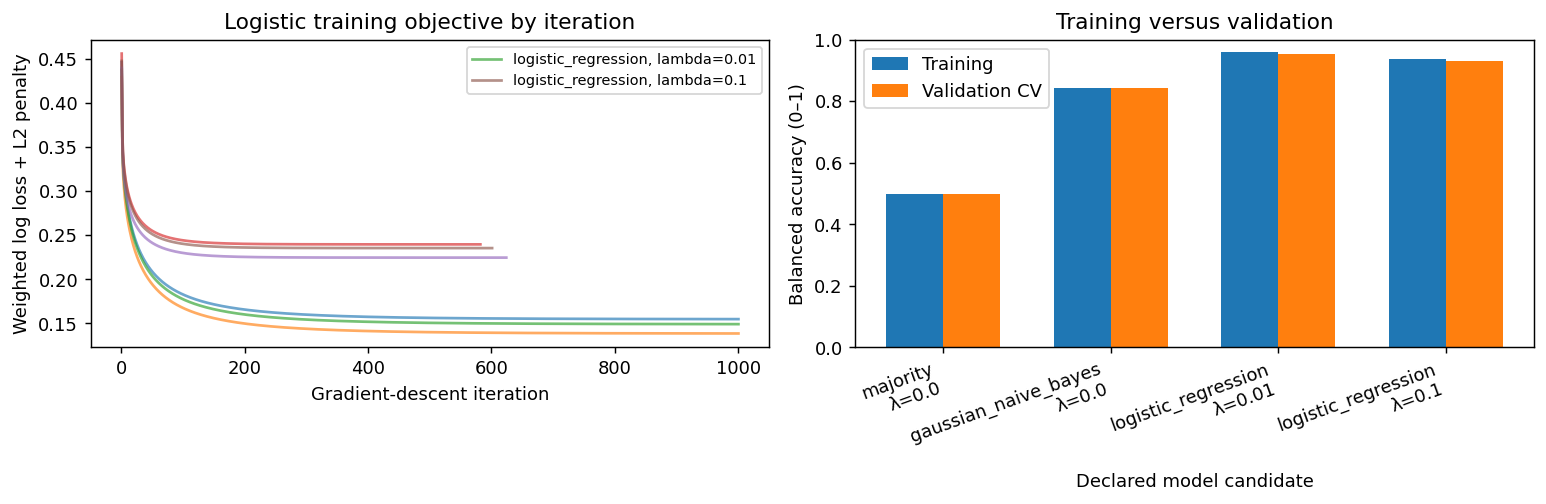

In [15]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for label,history in logistic_histories.items():
    axes[0].plot(np.arange(1,len(history)+1),history,label=label.split(', fold=')[0],alpha=.65)
axes[0].set(title='Logistic training objective by iteration',xlabel='Gradient-descent iteration',ylabel='Weighted log loss + L2 penalty')
handles,labels=axes[0].get_legend_handles_labels(); unique=dict(zip(labels,handles)); axes[0].legend(unique.values(),unique.keys(),fontsize=8)
locations=np.arange(len(comparisons))
axes[1].bar(locations-.17,[r['training_balanced_accuracy'] for r in comparisons],width=.34,label='Training')
axes[1].bar(locations+.17,[r['cv_balanced_accuracy'] for r in comparisons],width=.34,label='Validation CV')
axes[1].set_xticks(locations,[f"{r['model']}\nλ={r['regularization']}" for r in comparisons],rotation=20,ha='right')
axes[1].set(title='Training versus validation',xlabel='Declared model candidate',ylabel='Balanced accuracy (0–1)',ylim=(0,1)); axes[1].legend()
show_figure('05_training_and_cv.png')

## 17. Fit the selected model and evaluate the held-out test

Refit the scaler on all development rows, then train the selected model using only development labels. Evaluate test exactly at the **predeclared threshold 0.5**. The test score never changes the winner, features, λ or threshold.

These are results for an audited/deduplicated internal benchmark. They are not directly equivalent to results using the original unfiltered split, nor to external-hospital performance.

In [16]:
final_scaler=fit_scaler(Xd)
final_model=train_model(winner['model'],scale(Xd,final_scaler),yd,regularization=winner['regularization'])
test_score=predict_score(final_model,scale(Xt,final_scaler))
test_prediction=(test_score>=.5).astype(int)
test_metrics=metrics(yt,test_score)
print('Selected model:',winner['model'],'lambda:',winner['regularization'])
for key,value in test_metrics.items(): print(f'{key}: {value:.4f}' if isinstance(value,float) else f'{key}: {value}')
test_records=[r for r in retained if r['partition']=='test']
write_csv(OUTPUT/'test_predictions.csv',[dict(path=r['path'],group=r['group'],target=r['target'],score=float(s),prediction=int(p)) for r,s,p in zip(test_records,test_score,test_prediction)])

Selected model: logistic_regression lambda: 0.01
accuracy: 0.8350
balanced_accuracy: 0.7906
precision: 0.8078
recall: 0.9664
specificity: 0.6147
f1: 0.8800
roc_auc: 0.9240
tn: 142
fp: 89
fn: 13
tp: 374


## 18. Inspect errors and ROC

The confusion matrix reveals the operating-point tradeoff. Examine a fixed set of errors without retuning the model. The first eight mistakes in manifest order are not representative sampling of every failure mode, and we do not assign clinical explanations from image appearance alone.

Test mistakes: 102


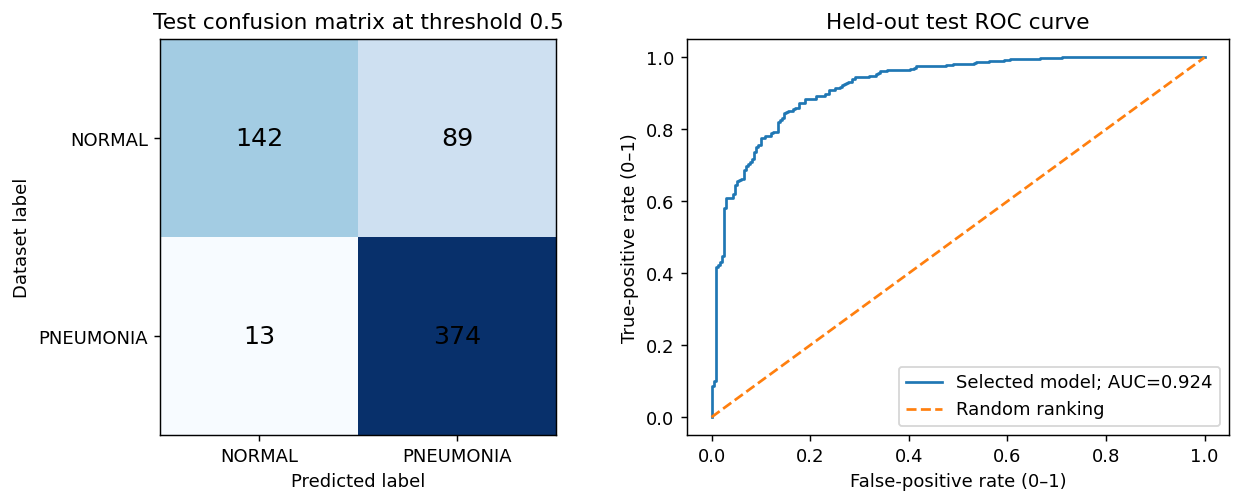

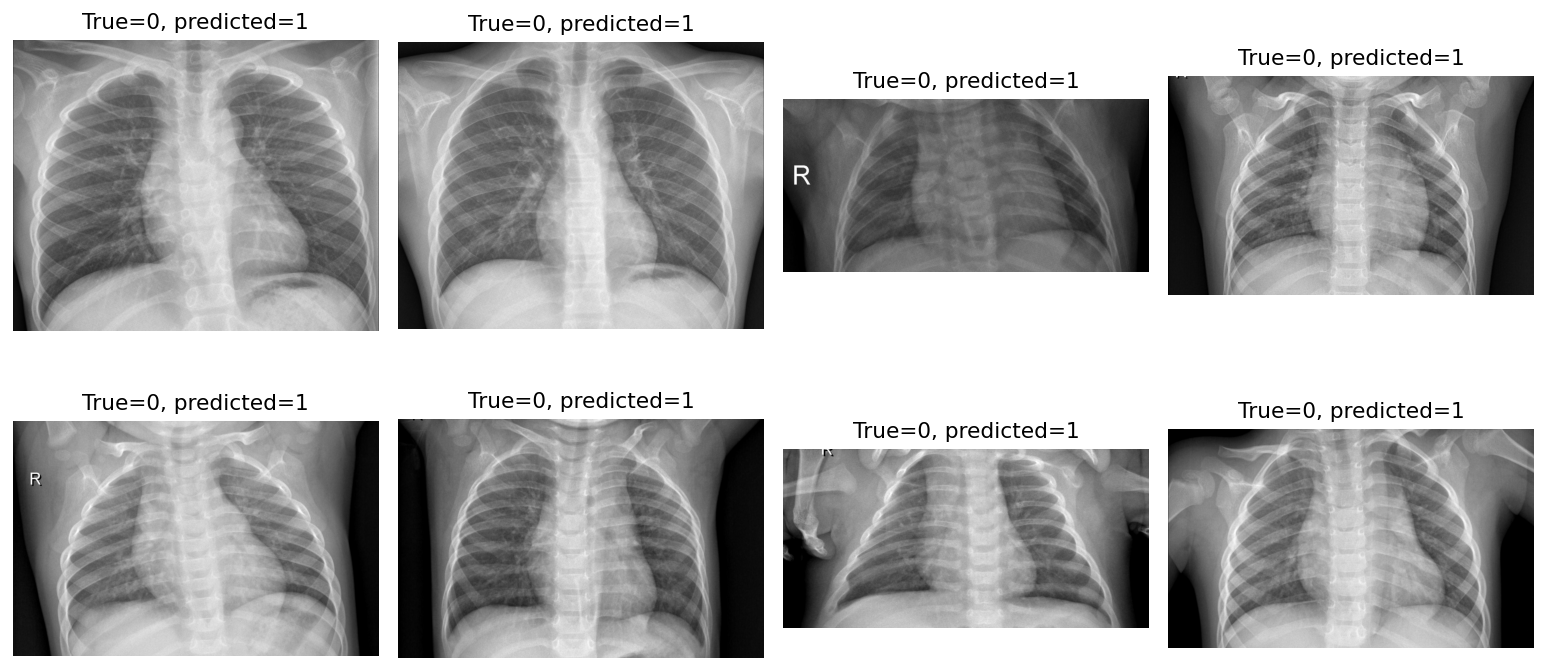

In [17]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
matrix=np.array([[test_metrics['tn'],test_metrics['fp']],[test_metrics['fn'],test_metrics['tp']]])
axes[0].imshow(matrix,cmap='Blues')
for row in range(2):
    for col in range(2): axes[0].text(col,row,str(matrix[row,col]),ha='center',va='center',fontsize=14)
axes[0].set_xticks([0,1],['NORMAL','PNEUMONIA']); axes[0].set_yticks([0,1],['NORMAL','PNEUMONIA'])
axes[0].set(title='Test confusion matrix at threshold 0.5',xlabel='Predicted label',ylabel='Dataset label')
fpr,tpr=roc_points(yt,test_score)
axes[1].plot(fpr,tpr,label=f"Selected model; AUC={test_metrics['roc_auc']:.3f}")
axes[1].plot([0,1],[0,1],'--',label='Random ranking')
axes[1].set(title='Held-out test ROC curve',xlabel='False-positive rate (0–1)',ylabel='True-positive rate (0–1)'); axes[1].legend()
show_figure('06_test_evaluation.png')
error_indices=np.flatnonzero(test_prediction!=yt)
print('Test mistakes:',len(error_indices))
if len(error_indices):
    fig,axes=plt.subplots(2,4,figsize=(12,6))
    for ax in axes.ravel(): ax.axis('off')
    for ax,i in zip(axes.ravel(),error_indices[:8]):
        with Image.open(root/test_records[i]['path']) as im: ax.imshow(im.convert('L'),cmap='gray')
        ax.set_title(f'True={yt[i]}, predicted={test_prediction[i]}')
    show_figure('07_first_test_errors.png')

## 19. Feature ablation — test whether spatial features add value

Compare all 149 features with only the 21 global histogram/summary features. Hold logistic λ=0.01 fixed on the same development folds. This tests the value of spatial block summaries rather than changing models, folds and settings at once. It is a development-only control and does not revise the final model after test inspection.

In [18]:
ablation=[]
for label,indices in [('all_149_features',np.arange(149)),('global_only_21_features',np.arange(128,149))]:
    scores=[]
    for tr,va in folds:
        a,b=Xd[tr][:,indices],Xd[va][:,indices]
        scaler=fit_scaler(a)
        model=train_logistic(scale(a,scaler),yd[tr],regularization=.01)
        scores.append(metrics(yd[va],predict_score(model,scale(b,scaler)))['balanced_accuracy'])
    row=dict(features=label,lambda_fixed=.01,mean_cv_balanced_accuracy=float(np.mean(scores)),fold_std=float(np.std(scores)))
    ablation.append(row); print(row)
write_csv(OUTPUT/'feature_ablation.csv',ablation)

{'features': 'all_149_features', 'lambda_fixed': 0.01, 'mean_cv_balanced_accuracy': 0.9537735167542962, 'fold_std': 0.007736799309861048}
{'features': 'global_only_21_features', 'lambda_fixed': 0.01, 'mean_cv_balanced_accuracy': 0.8812260453697617, 'fold_std': 0.012295470905863005}


## 20. Quantify uncertainty with group resampling

Resample held-out filename/hash groups 500 times and compute percentile 95% intervals. **Why groups?** Repeated images from one apparent patient may be correlated. **Limitations:** proxies may be wrong, and these intervals condition on one fitted model; they exclude training/model-selection uncertainty and external population shifts. More bootstrap replicates would reduce Monte Carlo error.

In [19]:
def grouped_bootstrap(y, score, groups, repeats=500):
    """Percentile intervals conditional on a trained model and proxy groups."""
    rng = np.random.default_rng(SEED)
    unique = np.unique(groups)
    indices = {g: np.flatnonzero(groups == g) for g in unique}
    values = []
    for _ in range(repeats):
        sampled = rng.choice(unique, size=len(unique), replace=True)
        ids = np.concatenate([indices[g] for g in sampled])
        if len(np.unique(y[ids])) == 2:
            values.append(metrics(y[ids], score[ids]))
    return {key: [float(np.quantile([v[key] for v in values], 0.025)),
                  float(np.quantile([v[key] for v in values], 0.975))]
            for key in ("balanced_accuracy", "recall", "specificity", "f1", "roc_auc")}



intervals=grouped_bootstrap(yt,test_score,gt)
for key,bounds in intervals.items(): print(key,': 95% interval',tuple(round(v,4) for v in bounds))

balanced_accuracy : 95% interval (0.7571, 0.8239)
recall : 95% interval (0.9467, 0.9826)
specificity : 95% interval (0.5492, 0.6782)
f1 : 95% interval (0.8516, 0.9058)
roc_auc : 95% interval (0.899, 0.9436)


## 21. Save and validate the final experiment

Save numerical model parameters in NPZ/JSON rather than depending on a model-serialization library. Reload parameters and confirm scores agree. Record exact versions, settings, retained counts and metrics. No raw radiographs are included in the results archive.

In [20]:
parameters={'scaler_mean':final_scaler['mean'],'scaler_std':final_scaler['std']}
if final_model['kind']=='logistic': parameters.update(w=final_model['w'],b=np.array(final_model['b']))
elif final_model['kind']=='naive_bayes': parameters.update(means=final_model['means'],variances=final_model['variances'],prior=final_model['prior'])
else: parameters.update(score=np.array(final_model['score']))
np.savez_compressed(OUTPUT/'model_parameters.npz',**parameters)
loaded=np.load(OUTPUT/'model_parameters.npz')
reloaded={'kind':final_model['kind']}
for key in loaded.files:
    if not key.startswith('scaler_'): reloaded[key]=loaded[key]
reloaded_scaler={'mean':loaded['scaler_mean'],'std':loaded['scaler_std']}
assert np.allclose(test_score,predict_score(reloaded,scale(Xt,reloaded_scaler)))
assert not set(gd)&set(gt)
result={'experiment':'basic_from_scratch_149_features','seed':SEED,'selected_model':winner,
        'test_threshold':.5,'development_images':len(yd),'test_images':len(yt),
        'test_metrics':test_metrics,'bootstrap_95_intervals':intervals,
        'libraries':{'numpy':np.__version__,'Pillow':importlib.metadata.version('Pillow') if hasattr(importlib,'metadata') else 'see runtime','matplotlib':matplotlib.__version__},
        'python':platform.python_version(),'grouping_caveat':'filename/hash groups, not verified patient IDs',
        'execution_environment':'Colab' if IN_COLAB else 'Local Python'}
(OUTPUT/'final_results.json').write_text(json.dumps(result,indent=2))
(OUTPUT/'feature_names.json').write_text(json.dumps(names,indent=2))
print('PASS: reloaded model scores agree; development/test groups are disjoint.')
print('Saved all outputs to:',OUTPUT)

PASS: reloaded model scores agree; development/test groups are disjoint.
Saved all outputs to: /Users/ravichandrashinde/Chest-Xray-Pneumonia-ML/basic_phase1


## 22. Conclusions based on this run

Read the actual values below. A large CV-to-test gap or weak specificity must be discussed even if accuracy/AUC looks encouraging. The ablation provides evidence for the chosen representation within development; it is not an independent clinical validation.

In [21]:
print(f"Selected {winner['model']} using mean development CV balanced accuracy {winner['cv_balanced_accuracy']:.3f}.")
print(f"Held-out test: accuracy={test_metrics['accuracy']:.3f}, balanced accuracy={test_metrics['balanced_accuracy']:.3f}, recall={test_metrics['recall']:.3f}, specificity={test_metrics['specificity']:.3f}, ROC-AUC={test_metrics['roc_auc']:.3f}.")
print(f"False negatives={test_metrics['fn']}; false positives={test_metrics['fp']}.")
print('Development feature ablation:',ablation)
print('These are internal benchmark results with filename-derived grouping, not evidence of clinical readiness.')

Selected logistic_regression using mean development CV balanced accuracy 0.954.
Held-out test: accuracy=0.835, balanced accuracy=0.791, recall=0.966, specificity=0.615, ROC-AUC=0.924.
False negatives=13; false positives=89.
Development feature ablation: [{'features': 'all_149_features', 'lambda_fixed': 0.01, 'mean_cv_balanced_accuracy': 0.9537735167542962, 'fold_std': 0.007736799309861048}, {'features': 'global_only_21_features', 'lambda_fixed': 0.01, 'mean_cv_balanced_accuracy': 0.8812260453697617, 'fold_std': 0.012295470905863005}]
These are internal benchmark results with filename-derived grouping, not evidence of clinical readiness.


## 23. Instructor explanation guide — choices, alternatives and limitations

**Why classification?** The target is a categorical folder annotation. Regression would predict a continuous quantity and does not match the binary task.

**Why basic features instead of raw pixels?** The 149 summaries retain coarse spatial/intensity information, reduce computation and have explainable definitions. Raw pixels, richer texture descriptors or learned CNN features may preserve more detail, at greater complexity.

**Why logistic regression?** We can derive its weighted log-loss, regularizer, gradient and update. It provides a transparent linear baseline. Its linear boundary can miss interactions. Gaussian NB offers a simpler closed-form alternative with stronger distribution/independence assumptions; the data, rather than preference, selects between them.

**Why normalize and standardize?** Dividing by 255 fixes a pixel range; standardizing makes features comparable for optimization and L2 penalties. Only the latter estimates training-set statistics. Fitting it before splitting would leak validation/test information.

**Why group validation?** Images are not necessarily independent patients. Proxy grouping and exact deduplication reduce known leakage; verified patient metadata would be better. We cannot certify independence from filenames alone.

**Why not use the supplied validation set directly?** It has only 16 images. Three grouped development folds provide more observations for comparison. A single grouped holdout is simpler; five folds or nested CV offer different computational/estimation tradeoffs.

**Why λ tuning and class weighting?** λ controls coefficient shrinkage and bias/variance. Class weights balance training influence without synthesizing images. Both weights and scaling are learned per training fold. The tiny λ grid prioritizes an explainable experiment over exhaustive tuning.

**Why balanced accuracy and several test metrics?** Both classes matter despite imbalance. Recall alone may reward predicting almost everything as pneumonia. Specificity exposes the complementary failure. A fixed threshold prevents test-tuning; calibration or a clinically chosen threshold would require separate development and clinical evidence.

**How do we know the implementation works?** Finite-difference gradient checks, controlled AUC/scaling examples, decreasing optimization loss, group-isolation assertions, saved fold assignments and reloaded-model score agreement. These validate calculations, not real-world diagnostic safety.

**Evaluation history:** The supplied test images were also inspected in earlier project versions. They are excluded from all tuning calculations in this run, but are not a newly unseen research holdout; a fresh external test set is needed for stronger claims after iterative development.

**What remains limited?** Pediatric single-source data; unverified patient identity; incomplete near-duplicate detection; possible acquisition/marker/padding shortcuts; label noise; loss of fine image detail; correlated NB features; selection-biased development estimates; no external validation; no established probability calibration. Our features cannot establish that the model learned pathological rather than acquisition signals.

**What would we try next?** Reliable patient metadata, external validation, richer hand-crafted features and leakage-safe feature selection/PCA. Compare SVM/trees if the instructor allows additional methods. Use a fresh evaluation set for changes informed by the present test. Deep learning is outside this basic Phase 1 experiment.

**One-minute explanation:** “We audited the images, removed exact duplicates and test-linked proxy groups, summarized each image with 149 brightness/contrast features, and standardized features using training rows only. We implemented majority prediction, Gaussian Naive Bayes and regularized logistic regression ourselves. We compared them using the same grouped folds and balanced accuracy, refitted the winner on development, and reported accuracy, sensitivity, specificity, F1 and AUC on the reserved test. We checked gradients and saved-model predictions, and we reported the dataset and validation limitations.”

## 24. Download results (optional)

The ZIP contains metrics, fold assignments, numerical parameters, figures and feature names. It excludes radiographs and the feature cache. In Colab, uncomment the last two lines to download it.

In [22]:
archive=OUTPUT/'basic_phase1_results.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for path in OUTPUT.rglob('*'):
        if path.is_file() and path!=archive and path.name!='basic_features.npz': z.write(path,path.relative_to(OUTPUT))
print('Saved:',archive)
# from google.colab import files
# files.download(str(archive))

Saved: /Users/ravichandrashinde/Chest-Xray-Pneumonia-ML/basic_phase1/basic_phase1_results.zip
